# Spambase : détection de spam

Mini-projet Machine Learning, TAF MCE (IMT Atlantique).

Ce notebook applique le workflow défini dans `ml_workflow.py` (fonctions préfixées par `mw.`) au jeu Spambase de l'UCI.

## 0. Le problème et le choix de la métrique

On veut décider si un e-mail est un spam à partir de 57 statistiques sur son texte. La documentation du jeu insiste sur un point : *« False positives (marking good mail as spam) are very undesirable »*. Perdre un vrai e-mail dans les spams est bien plus gênant que laisser passer une publicité.

On se place donc dans le cadre de Neyman-Pearson : on fixe un taux de faux positifs maximal de 1 %, et on cherche à détecter le plus de spams possible sous cette contrainte. Pour comparer les modèles indépendamment du seuil, on utilise l'AUC-ROC.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ml_workflow as mw

SEED = 42
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 90

## 1. Import et contrôle des données

In [2]:
df_raw = mw.load_spambase("data")
print(df_raw.shape)
mw.describe_dataset(df_raw, "is_spam")

(4601, 58)


n_lignes                                  4601.000
n_features                                  57.000
valeurs_manquantes                           0.000
lignes_dupliquees                          391.000
doublons_X_avec_labels_contradictoires       3.000
proportion_positifs                          0.394
accuracy_classe_majoritaire                  0.606
dtype: float64

Pas de valeur manquante, mais l'imputation reste dans le pipeline (on la teste en 3.2).

En revanche, 391 lignes sont des doublons exacts. Avec 57 fréquences identiques au centième près, il s'agit très probablement du même e-mail. Les garder risquerait de placer un même e-mail à la fois dans le train et dans le test, ce qui rendrait le score optimiste. On les supprime donc avant la séparation, ce qui ne pose pas de problème puisque cette opération n'apprend rien des données.

Après suppression des doublons : 4210 e-mails, 57 variables, 39.9% de spams


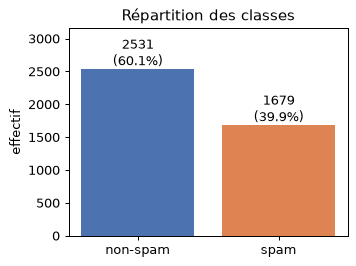

In [3]:
df = mw.remove_duplicates(df_raw)
X, y = mw.split_features_target(df, "is_spam")
print(f"Après suppression des doublons : {X.shape[0]} e-mails, {X.shape[1]} variables, {y.mean():.1%} de spams")
mw.plot_class_balance(y, labels=("non-spam", "spam"));

Le jeu est à peu près équilibré (40 % de spams). Le classifieur « toujours non-spam » obtient 60 % d'accuracy : c'est la référence à battre.

### Nature des variables

In [4]:
desc = pd.DataFrame({
    "part_de_zeros": (X == 0).mean(),
    "moyenne": X.mean(),
    "max": X.max(),
    "asymetrie": X.skew(),
})
print("Part moyenne de zéros :", f"{(X == 0).values.mean():.1%}")
desc.sort_values("max", ascending=False).head(8)

Part moyenne de zéros : 76.9%


,part_de_zeros,moyenne,max,asymetrie
capital_run_length_total,0.0000,291.1819,15841.000,8.8016
capital_run_length_longest,0.0000,52.1399,9989.000,31.2055
capital_run_length_average,0.0000,5.3839,1102.500,22.7607
word_freq_3d,0.9891,0.0631,42.810,27.2095
word_freq_george,0.8416,0.3698,33.330,9.4816
char_freq_!,0.4912,0.2811,32.478,18.3373
word_freq_edu,0.8812,0.1894,22.050,10.0770
word_freq_re,0.7036,0.3201,21.420,8.9179


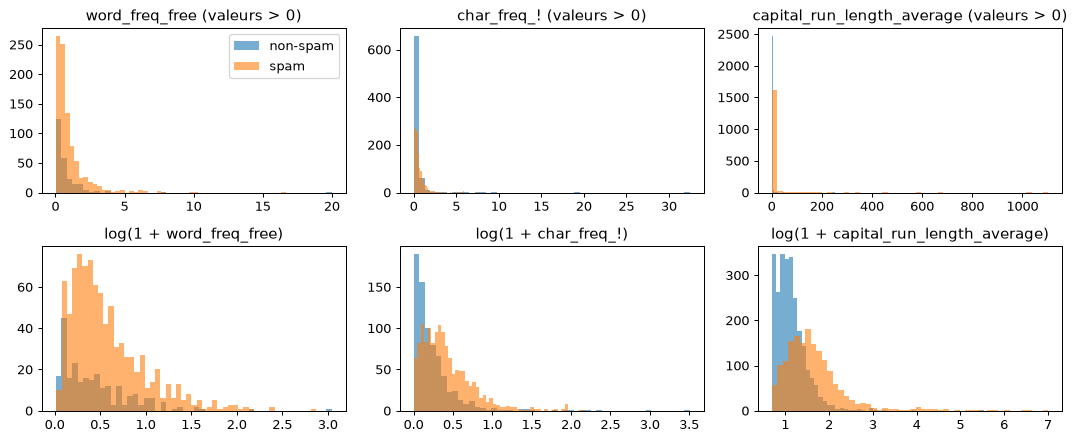

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5))
for j, col in enumerate(["word_freq_free", "char_freq_!", "capital_run_length_average"]):
    for c, lab in [(0, "non-spam"), (1, "spam")]:
        v = X.loc[(y == c) & (X[col] > 0), col]          # valeurs non nulles seulement
        axes[0, j].hist(v, bins=50, alpha=0.6, label=lab)
        axes[1, j].hist(np.log1p(v), bins=50, alpha=0.6, label=lab)
    axes[0, j].set_title(f"{col} (valeurs > 0)")
    axes[1, j].set_title(f"log(1 + {col})")
axes[0, 0].legend()
plt.tight_layout()

Trois constats guident le prétraitement :

1. Les échelles sont très différentes : les fréquences sont des pourcentages, alors que `capital_run_length_total` monte à 15 841. Il faut centrer et réduire.
2. Les variables sont très creuses (77 % de zéros) avec des queues lourdes. La transformation $\log(1+x)$ écrase ces queues (ligne du bas). Elle devrait aider les modèles linéaires et à distance, mais ne rien changer pour les arbres, qui ne dépendent que de l'ordre des valeurs.
3. L'hypothèse gaussienne de la LDA et de la QDA est clairement fausse ici.

## 2. Séparation train / test

La séparation est faite avant tout apprentissage, et stratifiée pour garder 40 % de spams des deux côtés. Le test (20 %) ne sert qu'une fois, à la toute fin. Tous les choix intermédiaires se font par validation croisée 5 plis sur le train.

In [6]:
X_train, X_test, y_train, y_test = mw.split_data(X, y, test_size=0.2, seed=SEED)
cv = mw.make_cv(5, SEED)
print(f"train : {X_train.shape}, {y_train.mean():.3f} de spams | test : {X_test.shape}, {y_test.mean():.3f} de spams")

SCORING = {
    "auc_roc": "roc_auc",
    "tpr_fpr1": mw.tpr_at_fpr_scorer(0.01),
    "accuracy": "accuracy",
    "precision": "precision",
    "f1": "f1",
}

train : (3368, 57), 0.399 de spams | test : (842, 57), 0.399 de spams


## 3. Prétraitement

### 3.1 Centrage-réduction codé à la main

`StandardScalerManual` apprend $\mu$ et $\sigma$ sur le train, puis les applique au test. On vérifie qu'il donne le même résultat que scikit-learn.

In [7]:
from sklearn.preprocessing import StandardScaler
ours = mw.StandardScalerManual().fit(X_train)
print("Identique à sklearn :", np.allclose(ours.transform(X_test), StandardScaler().fit(X_train).transform(X_test)))
Z_test = ours.transform(X_test)
print(f"Sur le TEST : moyennes dans [{Z_test.mean(0).min():.2f}, {Z_test.mean(0).max():.2f}], "
      f"écarts-types dans [{Z_test.std(0).min():.2f}, {Z_test.std(0).max():.2f}]")

Identique à sklearn : True
Sur le TEST : moyennes dans [-0.07, 0.08], écarts-types dans [0.25, 1.85]


Sur le test, les moyennes ne sont pas exactement nulles et les écarts-types pas exactement égaux à 1. C'est normal, et même rassurant : le test n'a pas servi à apprendre $\mu$ et $\sigma$.

### 3.2 Valeurs manquantes : moyenne ou médiane ?

Le jeu étant complet, on retire artificiellement 10 % puis 30 % des valeurs, et on compare l'imputation par la moyenne et par la médiane. Cette expérience utilise le test, mais seulement à titre d'illustration : elle ne sert à aucun choix du modèle final.

In [8]:
for name, model in [("Régression logistique", mw.LogisticRegressionGD()),
                    ("Gradient Boosting", mw.get_models(SEED)["Gradient Boosting (hist.)"])]:
    res = mw.missing_values_experiment(
        lambda s: mw.build_pipeline(model, impute=s, log_transform=True),
        X_train, y_train, X_test, y_test, rates=(0.0, 0.1, 0.3), seed=SEED)
    print(name); display(res)

Régression logistique


imputation,mean,median
taux_manquant,,
0.0,0.9812,0.9812
0.1,0.9739,0.9760
0.3,0.9628,0.9706


Gradient Boosting


imputation,mean,median
taux_manquant,,
0.0,0.9897,0.9897
0.1,0.9841,0.9838
0.3,0.9748,0.9781


La médiane fait mieux, surtout à 30 % de valeurs manquantes (0,971 contre 0,963 pour la régression logistique).

C'est logique avec des variables aussi creuses : la médiane vaut le plus souvent 0, ce qui correspond à un e-mail typique. La moyenne, elle, est tirée vers le haut par quelques valeurs extrêmes, et l'utiliser revient à inventer des mots absents de l'e-mail.

On retient donc l'imputation par la médiane.

## 4. ACP (codée à la main)

`PCAManual` diagonalise la matrice de covariance des données centrées-réduites, $C = \frac{1}{n-1}X_c^\top X_c = V\Lambda V^\top$, puis projette sur les premiers vecteurs propres. Les valeurs propres donnent la variance le long de chaque axe.

Variances expliquées identiques à sklearn : True
Axes identiques au signe près : True
Signes des 10 premiers axes, nous vs sklearn : [1 1 1 1 1 1 1 1 1 1]


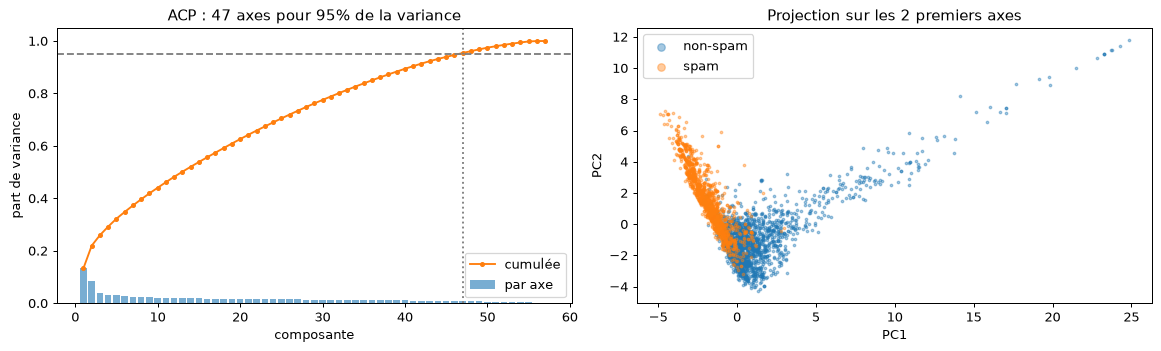

In [9]:
from sklearn.decomposition import PCA
prep = mw.build_pipeline(None, log_transform=True)      # imputation -> log1p -> centrage-réduction
Z_train = prep.fit_transform(X_train)
pca = mw.PCAManual(n_components=0.95).fit(Z_train)
ref = PCA(n_components=pca.n_components_).fit(Z_train)
print("Variances expliquées identiques à sklearn :", np.allclose(pca.explained_variance_, ref.explained_variance_))
print("Axes identiques au signe près :", np.allclose(np.abs(pca.components_), np.abs(ref.components_)))
print("Signes des 10 premiers axes, nous vs sklearn :",
      np.sign((pca.components_[:10] * ref.components_[:10]).sum(1)).astype(int))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
mw.plot_pca_variance(pca, 0.95, ax=axes[0])
mw.plot_pca_2d(pca.transform(Z_train), y_train, labels=("non-spam", "spam"), ax=axes[1])
plt.tight_layout()

Notre ACP retrouve exactement les variances et les axes de scikit-learn. Les signes coïncident aussi, parce qu'on a adopté la même convention (un vecteur propre n'est défini qu'au signe près).

Il faut 47 axes sur 57 pour garder 95 % de la variance : l'ACP compresse mal ce jeu. La projection sur les deux premiers axes montre tout de même une séparation partielle, ce qui n'est pas mal pour une méthode qui ignore complètement le label.

## 5. Comparaison des modèles

On compare des modèles de familles variées : régression logistique (codée à la main, par descente de gradient), LDA et QDA (codées à la main), Bayes naïf, kNN, SVM à noyau RBF, arbres et ensembles d'arbres, et un petit MLP. Chaque modèle est placé dans un pipeline imputation → (log) → centrage-réduction, réentraîné dans chaque pli.

On commence par vérifier que nos implémentations donnent les mêmes résultats que scikit-learn.

Régression logistique : 2948 itérations, écart max des coefficients avec sklearn = 8.3e-04, prédictions identiques sur le test : 100.0%
LDA : prédictions identiques à sklearn sur le test : 100.0%


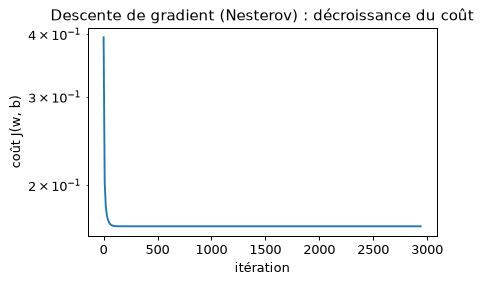

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
Ztr, Zte = Z_train, prep.transform(X_test)
gd = mw.LogisticRegressionGD(C=1.0).fit(Ztr, y_train)
sk = LogisticRegression(C=1.0, max_iter=10000, tol=1e-10).fit(Ztr, y_train)
print(f"Régression logistique : {gd.n_iter_} itérations, écart max des coefficients avec sklearn = "
      f"{np.abs(gd.coef_ - sk.coef_).max():.1e}, prédictions identiques sur le test : "
      f"{(gd.predict(Zte) == sk.predict(Zte)).mean():.1%}")
lda = mw.GaussianBayesClassifier("shared", reg=0).fit(Ztr, y_train)
lda_sk = LinearDiscriminantAnalysis(solver="lsqr").fit(Ztr, y_train)
print(f"LDA : prédictions identiques à sklearn sur le test : {(lda.predict(Zte) == lda_sk.predict(Zte)).mean():.1%}")

plt.figure(figsize=(5, 3))
plt.plot(np.arange(len(gd.loss_history_)) * 10, gd.loss_history_)
plt.xlabel("itération"); plt.ylabel("coût J(w, b)"); plt.yscale("log")
plt.title("Descente de gradient (Nesterov) : décroissance du coût");

### 5.1 Effet de la transformation log(1 + x)

In [11]:
models = mw.get_models(SEED)
res_raw = mw.cross_validate_models({k: mw.build_pipeline(m) for k, m in models.items()},
                                   X_train, y_train, SCORING, cv, verbose=False)
res_log = mw.cross_validate_models({k: mw.build_pipeline(m, log_transform=True) for k, m in models.items()},
                                   X_train, y_train, SCORING, cv, verbose=False)
comparison = pd.DataFrame({
    "AUC brut": res_raw["auc_roc_moy"], "AUC log": res_log["auc_roc_moy"],
    "rappel@TFP1% brut": res_raw["tpr_fpr1_moy"], "rappel@TFP1% log": res_log["tpr_fpr1_moy"],
}).sort_values("AUC log", ascending=False)
comparison

,AUC brut,AUC log,rappel@TFP1% brut,rappel@TFP1% log
modele,,,,
Gradient Boosting (hist.),0.9849,0.9849,0.7857,0.7857
Random Forest,0.9816,0.9816,0.8042,0.8028
MLP (1 couche cachée),0.9727,0.9796,0.6643,0.7372
"Régression logistique (GD, à la main)",0.9663,0.9766,0.4908,0.6680
SVM RBF,0.9685,0.9760,0.6032,0.7089
kNN,0.9614,0.9744,0.6352,0.6888
LDA (à la main),0.9513,0.9720,0.3934,0.6240
QDA (à la main),0.9429,0.9597,0.0918,0.1142
Bayes naïf gaussien,0.9244,0.9436,0.0000,0.0000


Comme prévu, $\log(1+x)$ améliore tous les modèles qui ne sont pas des arbres. L'effet se voit surtout sur le rappel à 1 % de faux positifs, qui passe de 0,49 à 0,67 pour la régression logistique et de 0,39 à 0,62 pour la LDA.

Pour les arbres, rien ne change, puisqu'une transformation croissante ne modifie pas l'ordre des valeurs. On garde donc `log1p` pour tous les modèles non arborescents. Voici les résultats détaillés :

In [12]:
cols = ["auc_roc_moy", "auc_roc_std", "tpr_fpr1_moy", "tpr_fpr1_std", "accuracy_moy", "precision_moy",
        "f1_moy", "auc_roc_train", "temps_fit_s"]
res_log[cols]

,auc_roc_moy,auc_roc_std,tpr_fpr1_moy,tpr_fpr1_std,accuracy_moy,precision_moy,f1_moy,auc_roc_train,temps_fit_s
modele,,,,,,,,,
Gradient Boosting (hist.),0.9849,0.0046,0.7857,0.1008,0.9504,0.9416,0.9376,0.9990,0.1636
Random Forest,0.9816,0.0068,0.8028,0.0604,0.9466,0.9486,0.9319,0.9990,0.1841
MLP (1 couche cachée),0.9796,0.0069,0.7372,0.0805,0.9368,0.9284,0.9201,0.9868,0.0801
"Régression logistique (GD, à la main)",0.9766,0.0048,0.6680,0.0732,0.9326,0.9233,0.9149,0.9833,0.0939
SVM RBF,0.9760,0.0083,0.7089,0.1130,0.9391,0.9378,0.9224,0.9861,0.0467
kNN,0.9744,0.0070,0.6888,0.0292,0.9320,0.9265,0.9136,1.0000,0.0074
LDA (à la main),0.9720,0.0090,0.6240,0.1530,0.9240,0.9367,0.9011,0.9747,0.0079
QDA (à la main),0.9597,0.0085,0.1142,0.2284,0.8426,0.7318,0.8290,0.9659,0.0080
Bayes naïf gaussien,0.9436,0.0114,0.0000,0.0000,0.8299,0.7161,0.8173,0.9506,0.0079


Tous les modèles battent nettement la référence, et les ensembles d'arbres arrivent en tête avec environ 80 % des spams détectés à 1 % de faux positifs. Ils captent des interactions (« beaucoup de `!` et beaucoup de majuscules ») qu'un modèle linéaire ne représente pas.

Les modèles génératifs gaussiens sont les plus faibles, ce qui confirme que leur hypothèse ne tient pas. Le cas du Bayes naïf est parlant : son AUC est correcte (0,94) mais son rappel à 1 % est nul. Ses probabilités, produits de 57 vraisemblances supposées indépendantes, saturent à 0 ou 1 pour beaucoup d'e-mails, spams comme non-spams, et aucun seuil ne permet alors de rester sous 1 % de faux positifs.

Un mot de prudence : ce critère est bruité (écart-type de 0,06 à 0,10). Un pli de validation ne contient qu'environ 500 non-spams, donc 1 % représente 5 e-mails, et il ne faut pas sur-interpréter des écarts de quelques points.

### 5.2 Biais et variance : courbe de validation du kNN et courbe d'apprentissage

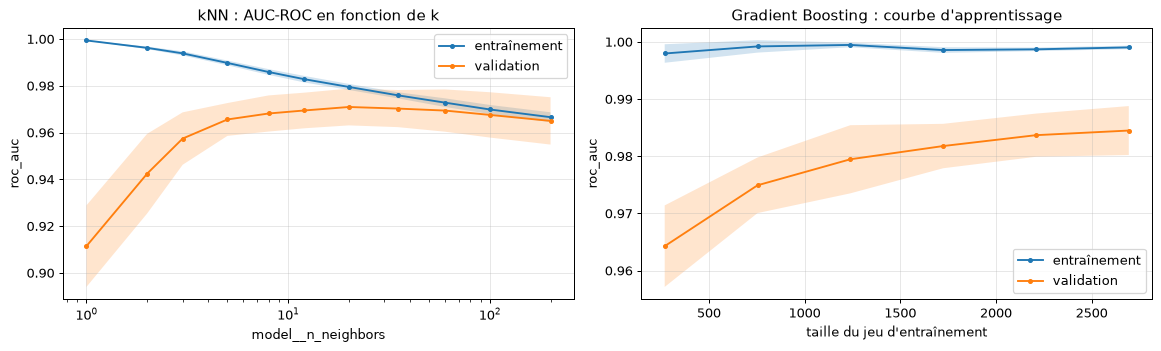

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
knn_pipe = mw.build_pipeline(mw.clone(models["kNN"]).set_params(weights="uniform"), log_transform=True)
mw.plot_validation_curve(knn_pipe, X_train, y_train, "model__n_neighbors", [1, 2, 3, 5, 8, 12, 20, 35, 60, 100, 200],
                         "roc_auc", cv, log_x=True, ax=axes[0])
axes[0].set_title("kNN : AUC-ROC en fonction de k")
mw.plot_learning_curve(mw.build_pipeline(models["Gradient Boosting (hist.)"]), X_train, y_train, "roc_auc", cv,
                       ax=axes[1], title="Gradient Boosting : courbe d'apprentissage")
plt.tight_layout()

Le kNN illustre bien le compromis biais-variance. Avec $k=1$, le score d'entraînement est parfait mais la validation tombe à 0,91. Elle atteint ensuite un plateau entre $k \approx 10$ et $50$, puis redescend doucement quand le voisinage devient trop large. Notre valeur par défaut, $k=15$, est sur le plateau.

Pour le Gradient Boosting, le score de validation continue de monter avec la taille du train (de 0,964 à 0,985) : plus de données l'amélioreraient encore un peu.

### 5.3 Réglage des hyperparamètres des meilleurs candidats

Recherche par grille en validation croisée, avec comme critère le rappel à 1 % de faux positifs.

In [14]:
grids = {
    "Gradient Boosting (hist.)": (mw.build_pipeline(models["Gradient Boosting (hist.)"]),
        {"model__learning_rate": [0.05, 0.1], "model__max_leaf_nodes": [15, 31, 63],
         "model__l2_regularization": [0.0, 1.0], "model__max_iter": [500]}),
    "Random Forest": (mw.build_pipeline(models["Random Forest"]),
        {"model__max_features": ["sqrt", 0.2, 0.33], "model__min_samples_leaf": [1, 2, 5],
         "model__n_estimators": [300]}),
    "SVM RBF": (mw.build_pipeline(models["SVM RBF"], log_transform=True),
        {"model__C": [0.3, 1, 3, 10, 30], "model__gamma": ["scale", 0.003, 0.01, 0.03]}),
    "Régression logistique (GD, à la main)": (mw.build_pipeline(models["Régression logistique (GD, à la main)"], log_transform=True),
        {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}),
    "MLP (1 couche cachée)": (mw.build_pipeline(models["MLP (1 couche cachée)"], log_transform=True),
        {"model__hidden_layer_sizes": [(32,), (64,), (128,), (64, 32)], "model__alpha": [1e-4, 1e-3, 1e-2, 1e-1]}),
}
tuned, tuned_rows = {}, []
for name, (pipe, grid) in grids.items():
    best, table = mw.tune_model(pipe, grid, X_train, y_train, mw.tpr_at_fpr_scorer(0.01), cv)
    tuned[name] = best
    tuned_rows.append({"modele": name, "meilleurs_parametres": table.iloc[[0], :-2].to_dict("records")[0],
                       "rappel@TFP1%_CV": table.loc[0, "mean_test_score"], "ecart_type": table.loc[0, "std_test_score"]})
pd.set_option("display.max_colwidth", None)
tuning_summary = pd.DataFrame(tuned_rows).set_index("modele").sort_values("rappel@TFP1%_CV", ascending=False)
tuning_summary

,meilleurs_parametres,rappel@TFP1%_CV,ecart_type
modele,,,
Random Forest,"{'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}",0.8258,0.0522
Gradient Boosting (hist.),"{'l2_regularization': 1.0, 'learning_rate': 0.05, 'max_iter': 500, 'max_leaf_nodes': 31}",0.8087,0.0686
SVM RBF,"{'C': 10.0, 'gamma': 0.01}",0.7491,0.0928
MLP (1 couche cachée),"{'alpha': 0.01, 'hidden_layer_sizes': (64, 32)}",0.7431,0.1014
"Régression logistique (GD, à la main)",{'C': 0.1},0.6836,0.1000


Le réglage fait gagner quelques points au SVM, au boosting et à la forêt, et presque rien à la régression logistique, dont la frontière reste linéaire quel que soit $C$.

Random Forest et Gradient Boosting sont au coude à coude (0,826 ± 0,052 contre 0,809 ± 0,069), avec un écart bien inférieur à un écart-type. On retient la forêt, qui a le meilleur score moyen, mais le boosting serait un choix tout aussi défendable.

## 6. Sélection de variables

### 6.1 Pourquoi la sélection doit se faire dans la validation croisée

Petite expérience : 100 individus, 5 000 variables de bruit pur et des labels tirés au hasard, donc une accuracy honnête de 50 %. On compare une sélection des 50 meilleures variables faite sur tout le jeu avant la validation croisée (a), et la même sélection placée dans le pipeline (b).

In [15]:
mw.selection_leakage_demo(n_samples=100, n_features=5000, k=50, seed=0)

(a) sélection hors CV (biaisé)    0.92
(b) sélection dans le pipeline    0.51
dtype: float64

En (a), la sélection a vu les plis de validation : elle a retenu des variables corrélées au label par hasard sur ces individus, et la validation croisée annonce 92 % d'accuracy sur du bruit. C'est pour cela que toutes nos sélections sont des étapes du pipeline.

### 6.2 Classement des variables selon quatre critères

Variables mises à zéro par la pénalité L1 (C = 0,05) : 18 sur 57


,anova_F,info_mutuelle,abs_coef_L1,permutation_RF,rang_moyen
char_freq_!,865.4565,0.1944,0.5734,0.0087,2.75
word_freq_remove,666.9258,0.1470,0.7259,0.0115,4.00
char_freq_$,724.8991,0.1696,0.6339,0.0058,4.25
word_freq_hp,536.3235,0.1245,1.1353,0.0083,5.50
word_freq_free,717.5003,0.1452,0.5063,0.0060,5.50
capital_run_length_longest,1101.5382,0.1708,0.3265,0.0023,5.75
capital_run_length_average,801.0528,0.1607,0.3069,0.0033,7.00
word_freq_george,274.2992,0.0917,0.8012,0.0028,9.50
word_freq_000,536.8449,0.1041,0.3790,0.0014,10.25
word_freq_your,915.6569,0.1438,0.2244,0.0009,10.75


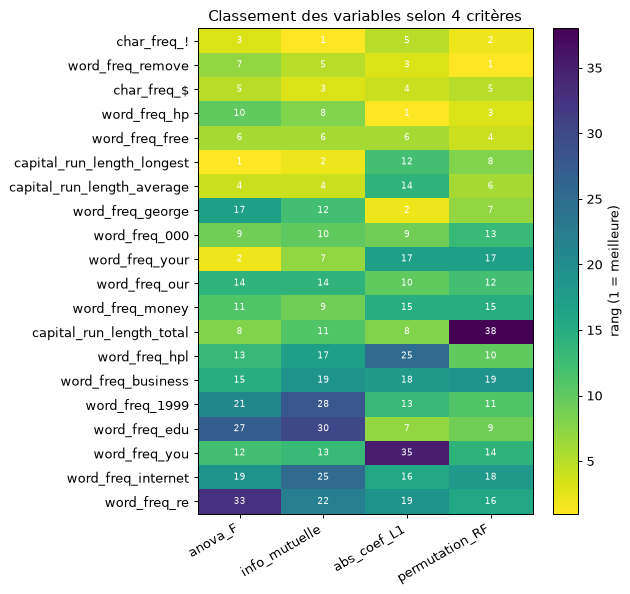

In [16]:
X_train_log = np.log1p(X_train)          # transformation monotone : ne change que ANOVA et L1
ranking = mw.rank_features(X_train_log, y_train, seed=SEED)
mw.plot_feature_ranking(ranking, top=20)
print("Variables mises à zéro par la pénalité L1 (C = 0,05) :", int((ranking["abs_coef_L1"] == 0).sum()), "sur", len(ranking))
ranking[["anova_F", "info_mutuelle", "abs_coef_L1", "permutation_RF", "rang_moyen"]].head(12)

Les critères s'accordent sur le haut du classement : `!`, `$`, `remove`, `free`, `money` et les suites de majuscules. C'est bien le vocabulaire du spam commercial.

Quelques désaccords méritent d'être relevés :
- `capital_run_length_total` est 8e pour l'ANOVA mais 38e par permutation, car elle est redondante avec `_longest` et `_average` : quand on la mélange, la forêt se rabat sur les deux autres ;
- `your` est 2e pour l'ANOVA mais 17e pour la L1, pour la même raison : très liée au spam prise seule, elle n'apporte presque rien en plus des autres mots commerciaux.

Enfin, `hp` et `george` font partie des variables les plus utiles. Le jeu vient de la boîte mail d'un employé de HP prénommé George : le modèle apprend donc en partie cette boîte mail, et pas seulement le spam en général.

### 6.3 Score en fonction du nombre de variables gardées

Filtre par information mutuelle placé dans le pipeline, pour la régression logistique et le Gradient Boosting.

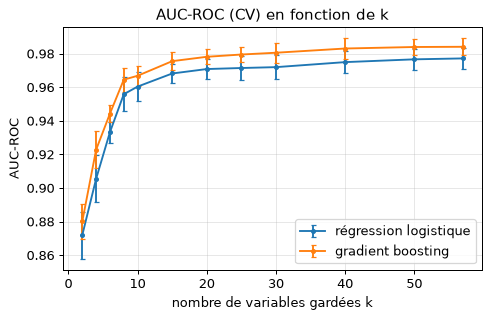

In [17]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from functools import partial
mi = partial(mutual_info_classif, random_state=SEED)
ks = [2, 4, 6, 8, 10, 15, 20, 25, 30, 40, 50, 57]
best_lr = tuned["Régression logistique (GD, à la main)"].named_steps["model"]
best_gb = tuned["Gradient Boosting (hist.)"].named_steps["model"]
curve_lr = mw.cv_score_vs_k(lambda k: mw.build_pipeline(best_lr, log_transform=True, selector=SelectKBest(mi, k=k)),
                            X_train, y_train, ks, "roc_auc", cv)
curve_gb = mw.cv_score_vs_k(lambda k: mw.build_pipeline(best_gb, selector=SelectKBest(mi, k=k)),
                            X_train, y_train, ks, "roc_auc", cv)
ax = mw.plot_score_vs_k(curve_lr, "AUC-ROC", label="régression logistique")
mw.plot_score_vs_k(curve_gb, "AUC-ROC", ax=ax, label="gradient boosting")
ax.legend();

Le score monte vite jusqu'à 15–20 variables, puis continue de croître doucement. Retirer des variables n'améliore donc pas les résultats : avec 3 368 e-mails pour 57 variables, la régularisation suffit à contenir le sur-apprentissage. Avec 20 variables, on perd moins de 0,01 d'AUC.

### 6.4 Toutes les variables, une sélection (filtre, L1, RFE) ou l'ACP ?

In [18]:
from sklearn.feature_selection import SelectFromModel, RFECV
from sklearn.linear_model import LogisticRegression

l1_selector = SelectFromModel(LogisticRegression(penalty="l1", C=0.05, solver="liblinear", max_iter=5000,
                                                   random_state=SEED))
rfe_selector = RFECV(LogisticRegression(max_iter=5000), step=2, cv=mw.make_cv(3, SEED), scoring="roc_auc", n_jobs=-1)
variants = {
    "LR — 57 variables": mw.build_pipeline(best_lr, log_transform=True),
    "LR — filtre MI (k=25)": mw.build_pipeline(best_lr, log_transform=True, selector=SelectKBest(mi, k=25)),
    "LR — embarquée L1": mw.build_pipeline(best_lr, log_transform=True, selector=l1_selector),
    "LR — wrapper RFECV": mw.build_pipeline(best_lr, log_transform=True, selector=rfe_selector),
    "LR — ACP 95 %": mw.build_pipeline(best_lr, log_transform=True, pca=0.95),
    "GB — 57 variables": mw.build_pipeline(best_gb),
    "GB — filtre MI (k=25)": mw.build_pipeline(best_gb, selector=SelectKBest(mi, k=25)),
    "GB — ACP 95 %": mw.build_pipeline(best_gb, log_transform=True, pca=0.95),
    "kNN — 57 variables": mw.build_pipeline(models["kNN"], log_transform=True),
    "kNN — filtre MI (k=25)": mw.build_pipeline(models["kNN"], log_transform=True, selector=SelectKBest(mi, k=25)),
    "kNN — ACP 95 %": mw.build_pipeline(models["kNN"], log_transform=True, pca=0.95),
}
res_sel = mw.cross_validate_models(variants, X_train, y_train, SCORING, cv, verbose=False)
res_sel[["auc_roc_moy", "auc_roc_std", "tpr_fpr1_moy", "accuracy_moy", "temps_fit_s"]].sort_index()

,auc_roc_moy,auc_roc_std,tpr_fpr1_moy,accuracy_moy,temps_fit_s
modele,,,,,
GB — 57 variables,0.9841,0.0051,0.8087,0.9483,0.3237
GB — ACP 95 %,0.9819,0.0070,0.7700,0.9388,0.2557
GB — filtre MI (k=25),0.9795,0.0047,0.7662,0.9427,0.3213
LR — 57 variables,0.9772,0.0062,0.6836,0.9335,0.0484
LR — ACP 95 %,0.9766,0.0062,0.6702,0.9332,0.0502
LR — embarquée L1,0.9761,0.0069,0.6881,0.9311,0.0307
LR — filtre MI (k=25),0.9715,0.0072,0.6702,0.9276,0.1857
LR — wrapper RFECV,0.9770,0.0061,0.6910,0.9311,0.3942
kNN — 57 variables,0.9744,0.0070,0.6888,0.9320,0.0071


In [19]:
# Nombre de variables retenues par la sélection L1 et par RFECV (sur tout le train)
lr_l1 = variants["LR — embarquée L1"].fit(X_train, y_train)
lr_rfe = variants["LR — wrapper RFECV"].fit(X_train, y_train)
kept_l1 = X_train.columns[lr_l1.named_steps["select"].get_support()]
kept_rfe = X_train.columns[lr_rfe.named_steps["select"].get_support()]
print(f"L1 garde {len(kept_l1)} variables, RFECV en garde {len(kept_rfe)}.")
print("Écartées par L1 :", sorted(set(X_train.columns) - set(kept_l1)))

L1 garde 39 variables, RFECV en garde 43.
Écartées par L1 : ['char_freq_(', 'char_freq_[', 'word_freq_415', 'word_freq_650', 'word_freq_857', 'word_freq_address', 'word_freq_addresses', 'word_freq_all', 'word_freq_direct', 'word_freq_email', 'word_freq_labs', 'word_freq_make', 'word_freq_order', 'word_freq_original', 'word_freq_parts', 'word_freq_people', 'word_freq_receive', 'word_freq_telnet']


Aucune méthode de réduction ne bat le modèle complet, mais certaines font aussi bien avec moins de variables. Pour la régression logistique, la sélection L1 (39 variables) et le RFECV (43 variables) atteignent la même AUC qu'avec les 57 variables.

L'ACP n'apporte rien, et dégrade même le boosting sur le critère métier (0,81 → 0,77) : les arbres coupent naturellement selon les variables d'origine, et les combinaisons de l'ACP n'ont pas de sens pour un seuil.

Les variables écartées par la L1 sont surtout des mots rares ou liés au contexte de HP (`415`, `650`, `857`, `telnet`, `labs`).

On garde finalement les 57 variables pour le modèle final. La sélection L1 reste intéressante pour obtenir un modèle linéaire plus compact.

## 7. Choix du modèle, du seuil, puis évaluation finale

### 7.1 Seuil de Neyman-Pearson

Le seuil par défaut de 0,5 ne tient pas compte de l'asymétrie des coûts. On choisit plutôt le plus petit seuil qui garde un taux de faux positifs sous 1 %. Pour ne pas toucher au test, il est calculé sur les scores hors pli du train : chaque e-mail est scoré par un modèle qui ne l'a pas vu.

Modèle retenu : Random Forest
Seuil de Neyman-Pearson (TFP ≤ 1 % hors pli sur le train) : 0.762


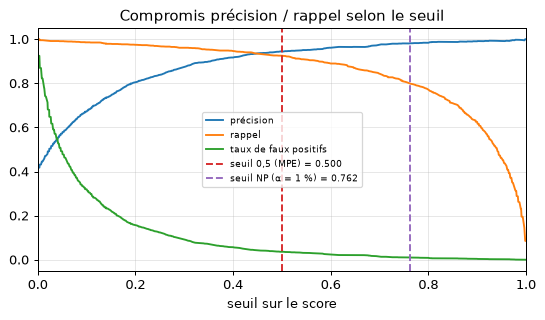

In [20]:
FINAL_NAME = tuning_summary.index[0]      # meilleur critère métier en validation croisée (section 5.3)
final_model = tuned[FINAL_NAME]
oof = mw.out_of_fold_scores(final_model, X_train, y_train, cv)
thr_np = mw.neyman_pearson_threshold(y_train, oof, alpha=0.01)
print(f"Modèle retenu : {FINAL_NAME}")
print(f"Seuil de Neyman-Pearson (TFP ≤ 1 % hors pli sur le train) : {thr_np:.3f}")
mw.plot_threshold_tradeoff(y_train, oof, {"seuil 0,5 (MPE)": 0.5, "seuil NP (α = 1 %)": thr_np});

### 7.2 Évaluation finale (le test n'est utilisé qu'ici)

,auc_roc,accuracy,precision,rappel,taux_faux_positifs,f1,FP,FN
"Random Forest, seuil 0,5",0.9894,0.9466,0.9477,0.9167,0.0336,0.9319,17.0,28.0
"Random Forest, seuil NP",0.9894,0.9216,0.9927,0.8095,0.0040,0.8918,2.0,64.0


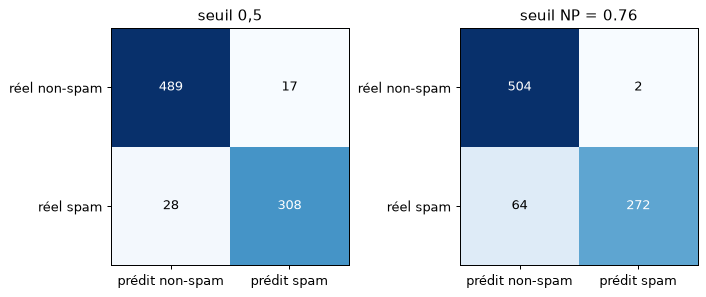

In [21]:
final_model.fit(X_train, y_train)
test_default = mw.evaluate_on_test(final_model, X_test, y_test)
test_np = mw.evaluate_on_test(final_model, X_test, y_test, threshold=thr_np)
cols = ["auc_roc", "accuracy", "precision", "rappel", "taux_faux_positifs", "f1", "FP", "FN"]
display(mw.results_table({f"{FINAL_NAME}, seuil 0,5": test_default, f"{FINAL_NAME}, seuil NP": test_np}, cols))

fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
mw.plot_confusion(test_default, ("non-spam", "spam"), ax=axes[0], title="seuil 0,5")
mw.plot_confusion(test_np, ("non-spam", "spam"), ax=axes[1], title=f"seuil NP = {thr_np:.2f}")
plt.tight_layout()

Au seuil 0,5, le modèle envoie 17 vrais e-mails sur 506 dans les spams, soit 3,4 % de faux positifs, bien au-delà du budget fixé.

Avec le seuil de Neyman-Pearson (0,76), il ne reste que 2 faux positifs (0,4 %), et 81 % des spams sont toujours détectés. Le prix à payer est de laisser passer 36 spams de plus, ce qui correspond exactement au compromis recherché.

Ces résultats sont cohérents avec la validation croisée (AUC de 0,989 sur le test, rappel de 0,81 contre 0,83). Le taux de faux positifs est même un peu sous la cible, ce qui n'est pas surprenant : le seuil a été estimé à partir d'une vingtaine d'e-mails seulement.

Pour situer le modèle retenu, on trace aussi les courbes ROC et PR des autres candidats sur le test. Ce graphique n'a servi à aucun choix.

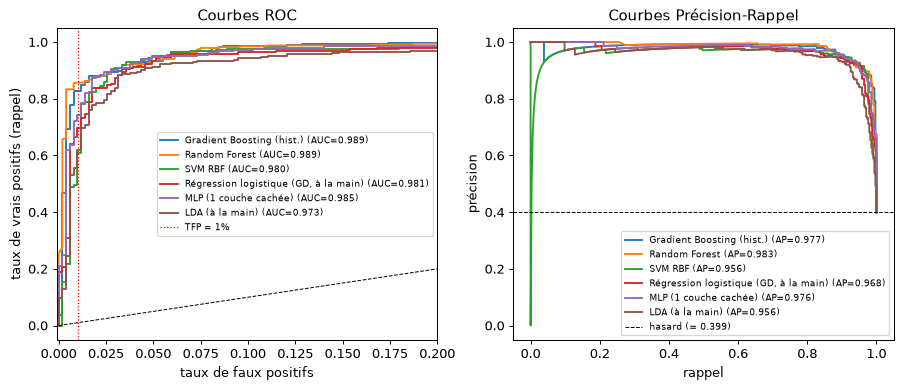

In [22]:
test_scores = {}
for name, model in tuned.items():
    model.fit(X_train, y_train)
    test_scores[name] = mw.get_scores(model, X_test)
lda_pipe = mw.build_pipeline(mw.GaussianBayesClassifier("shared", reg=1e-3), log_transform=True).fit(X_train, y_train)
test_scores["LDA (à la main)"] = mw.get_scores(lda_pipe, X_test)
mw.plot_roc_pr(test_scores, y_test, mark_fpr=0.01, roc_xmax=0.2);

## 8. Conclusion

Le modèle retenu est une Random Forest de 300 arbres sur les 57 variables, avec un seuil de Neyman-Pearson à 1 % de faux positifs. Sur le test, elle obtient une AUC de 0,989, détecte 81 % des spams et ne fait que 0,4 % de faux positifs.

La forêt et le boosting sont les meilleurs modèles en validation croisée, sans différence significative entre eux. Mais le choix du seuil compte au moins autant que celui du modèle : au seuil 0,5, la même forêt fait 8 fois plus de faux positifs.

Si l'interprétabilité est prioritaire, une régression logistique sur $\log(1+x)$ avec sélection L1 (39 variables) est une bonne alternative, au prix d'environ 14 points de rappel en moins à 1 % de faux positifs.

Ce qu'on retient de ce jeu :
- la forme des distributions compte plus que l'échelle, et `log1p` est le prétraitement le plus utile hors arbres ;
- l'ACP n'aide pas ;
- la sélection de variables n'améliore pas le score, mais donne un modèle linéaire plus compact ;
- les modèles gaussiens souffrent d'une hypothèse qui ne tient pas sur ces données.

Le jeu date de 1999 et vient d'une seule boîte mail, donc ces performances ne se transposeraient pas telles quelles à une autre messagerie.

Le notebook `diabetes.ipynb` applique le même workflow à un jeu déséquilibré.